In [212]:
import pandas as pd
import numpy as np
from pathlib import Path
import seaborn as sns
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch  
BASE_DIR = Path.cwd().resolve().parent
BASE_DIR

DATA_DIR = BASE_DIR / "data"
RAW_DIR = DATA_DIR / "raw"

ruta_provincias = BASE_DIR/ "data"/"procesado"/"LIM_DEPARTAMENTAL_PERU_MIN.json"

peru = gpd.read_file(ruta_mapa)

ruta_parquet = BASE_DIR/"data"/"raw"/"01_CARATULA.parquet"

datos = pd.read_parquet(ruta_parquet)


In [3]:
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 41164 entries, 0 to 41163
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ANIO              41164 non-null  int64  
 1   CCDD              39485 non-null  float64
 2   NOMBREDD          39485 non-null  str    
 3   CCPP              39485 non-null  float64
 4   NOMBREPV          39485 non-null  str    
 5   CCDI              39485 non-null  float64
 6   NOMBREDI          39485 non-null  str    
 7   NSEGM             41164 non-null  int64  
 8   ID_PROD           41164 non-null  int64  
 9   UA                41164 non-null  int64  
 10  RESFIN            41164 non-null  int64  
 11  REGION            41164 non-null  int64  
 12  ESTRATO           38457 non-null  float64
 13  FACTOR_PRODUCTOR  40136 non-null  float64
 14  CODIGO            41164 non-null  int64  
 15  LATITUD           39485 non-null  float64
 16  LONGITUD          39485 non-null  float64
dtypes: f

In [184]:
df_CARATULA = pd.read_parquet(RAW_DIR / "01_CARATULA.parquet")
df_cap200b = pd.read_parquet(RAW_DIR / "04_CAP200B_1.parquet")

In [13]:
df_CARATULA.info(verbose = True)

<class 'pandas.DataFrame'>
RangeIndex: 41164 entries, 0 to 41163
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ANIO              41164 non-null  int64  
 1   CCDD              39485 non-null  float64
 2   NOMBREDD          39485 non-null  str    
 3   CCPP              39485 non-null  float64
 4   NOMBREPV          39485 non-null  str    
 5   CCDI              39485 non-null  float64
 6   NOMBREDI          39485 non-null  str    
 7   NSEGM             41164 non-null  int64  
 8   ID_PROD           41164 non-null  int64  
 9   UA                41164 non-null  int64  
 10  RESFIN            41164 non-null  int64  
 11  REGION            41164 non-null  int64  
 12  ESTRATO           38457 non-null  float64
 13  FACTOR_PRODUCTOR  40136 non-null  float64
 14  CODIGO            41164 non-null  int64  
 15  LATITUD           39485 non-null  float64
 16  LONGITUD          39485 non-null  float64
dtypes: f

In [21]:
df_cap200b.info(verbose = True)

<class 'pandas.DataFrame'>
RangeIndex: 6021 entries, 0 to 6020
Data columns (total 33 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ANIO              6021 non-null   int64  
 1   CCDD              5984 non-null   float64
 2   NOMBREDD          5984 non-null   str    
 3   CCPP              5984 non-null   float64
 4   NOMBREPV          5984 non-null   str    
 5   CCDI              5984 non-null   float64
 6   NOMBREDI          5984 non-null   str    
 7   NSEGM             6021 non-null   int64  
 8   ID_PROD           6021 non-null   int64  
 9   UA                6021 non-null   int64  
 10  RESFIN            6021 non-null   int64  
 11  REGION            6021 non-null   int64  
 12  ESTRATO           5984 non-null   float64
 13  FACTOR_PRODUCTOR  6021 non-null   float64
 14  CODIGO            6021 non-null   int64  
 15  P101A             37 non-null     float64
 16  P142_1            6021 non-null   int64  
 17  P142_2

In [214]:
provincias = provincias_peru.copy()
provincias_ama = provincias_peru[
    provincias_peru["NOMBDEP"].str.upper().eq("AMAZONAS")
]

provincias_ama.head(5)

,OBJECTID_1,OBJECTID,CCDD,NOMBDEP,CCPP,NOMBPROV,CAPITAL,IDPROV,Shape_STAr,Shape_STLe,ORIG_FID,Shape_Leng,Shape_Area,geometry
100,111,101,01,AMAZONAS,02,BAGUA,BAGUA,0102,0.472370,4.294658,100,4.294658,0.472370,"POLYGON ((-78.10615 -5.342, -78.09676 -5.34128..."
101,112,102,01,AMAZONAS,03,BONGARA,JUMBILLA,0103,0.231319,3.038661,101,3.038661,0.231319,"POLYGON ((-77.69596 -5.41105, -77.70279 -5.380..."
102,113,103,01,AMAZONAS,01,CHACHAPOYAS,CHACHAPOYAS,0101,0.237605,3.872238,102,3.872238,0.237605,"POLYGON ((-77.67167 -5.9741, -77.68756 -5.9791..."
103,114,104,01,AMAZONAS,04,CONDORCANQUI,SANTA MARIA DE NIEVA,0104,1.455241,7.617350,103,7.617350,1.455241,"POLYGON ((-77.74529 -5.13302, -77.76757 -5.111..."
104,115,105,01,AMAZONAS,05,LUYA,LAMUD,0105,0.270145,2.868283,104,2.868283,0.270145,"POLYGON ((-77.89095 -6.10269, -77.90392 -6.092..."


In [46]:
df_amazonas = df_cap200b[df_cap200b["NOMBREDD"]=="AMAZONAS"].copy()

#### 1-. EN LOS ÚLTIMOS 12 MESES, LA EMPRESA O EL PRODUCTOR REALIZÓ ACTIVIDAD: ¿Agrícola? o ¿Pecuaria? (P142_1) (P142_2)

In [210]:
cols_p142 = ["P142_1", "P142_2"]

df_amazonas[cols_p142] = df_amazonas[cols_p142].apply(
    pd.to_numeric,
    errors="coerce"
)

sub_ama = df_amazonas[cols_p142]

In [139]:
nombres_actividades = [
    "Actividad Agrícola",
    "Actividad Pecuaria"
]

tabla_p142_ama = pd.DataFrame({
    "actividad": nombres_actividades,
    "si_realizo": [sub_ama[c].eq(1).sum() for c in cols_p142],
    "no_realizo": [sub_ama[c].eq(0).sum() for c in cols_p142]
})

tabla_p142_ama

,actividad,si_realizo,no_realizo
0,Actividad Agrícola,87,0
1,Actividad Pecuaria,68,19


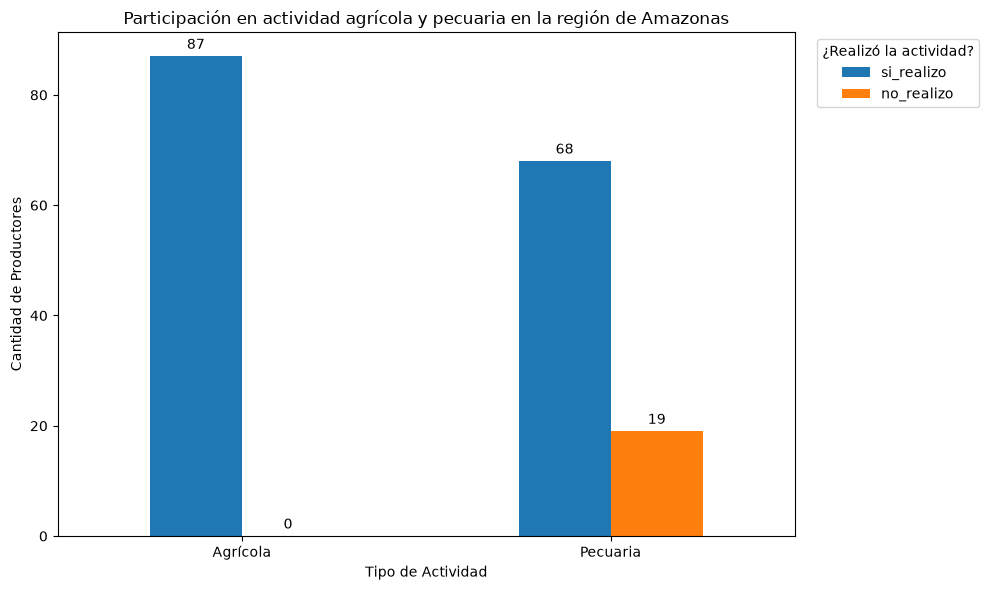

In [205]:
gr_reg_tipo_ama = tabla_p142_ama.plot(
    kind="bar",
    stacked=False,
    figsize=(10, 6),
)

gr_reg_tipo_ama.set_title("Participación en actividad agrícola y pecuaria en la región de Amazonas")
gr_reg_tipo_ama.set_xlabel("Tipo de Actividad")
gr_reg_tipo_ama.set_ylabel("Cantidad de Productores")  

gr_reg_tipo_ama.legend(
    title="¿Realizó la actividad?",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

for container in gr_reg_tipo_ama.containers:
    gr_reg_tipo_ama.bar_label(
        container,
        fmt="%d",
        label_type="edge",  
        padding=3,         
        fontsize=10
    )

plt.xticks(ticks=[0, 1], labels=["Agrícola", "Pecuaria"], rotation=0)

plt.tight_layout()
plt.show()

### 2-. Cultivos que sufrieron pérdida total de producción o superficie(P224B)

In [146]:
df_ama_p224b = df_amazonas.dropna(subset=["P224B_NOM"])

}tabla_p224b_ama = df_ama_p224b["P224B_NOM"].value_counts().reset_index()
tabla_p224b_ama.columns = ["cultivo_afectado", "cantidad_casos"]

total_casos = tabla_p224b_ama["cantidad_casos"].sum()
tabla_p224b_ama["porcentaje"] = (tabla_p224b_ama["cantidad_casos"] / total_casos) * 100

tabla_p224b_ama = tabla_p224b_ama.sort_values("cantidad_casos", ascending=False).reset_index(drop=True)

display(tabla_p224b_ama)


df_grafico_p224b = tabla_p224b_ama.set_index("cultivo_afectado")[["porcentaje"]]

,cultivo_afectado,cantidad_casos,porcentaje
0,MAIZ AMARILLO DURO,17,19.540230
1,PLATANO,13,14.942529
2,ARROZ CASCARA,10,11.494253
3,FRIJOL PINTO,6,6.896552
4,CAFE PERGAMINO,6,6.896552
5,NARANJO,4,4.597701
6,MAIZ AMILACEO,3,3.448276
7,YUCA,3,3.448276
8,PAPA BLANCA,2,2.298851
9,FRIJOL SHINGO,2,2.298851


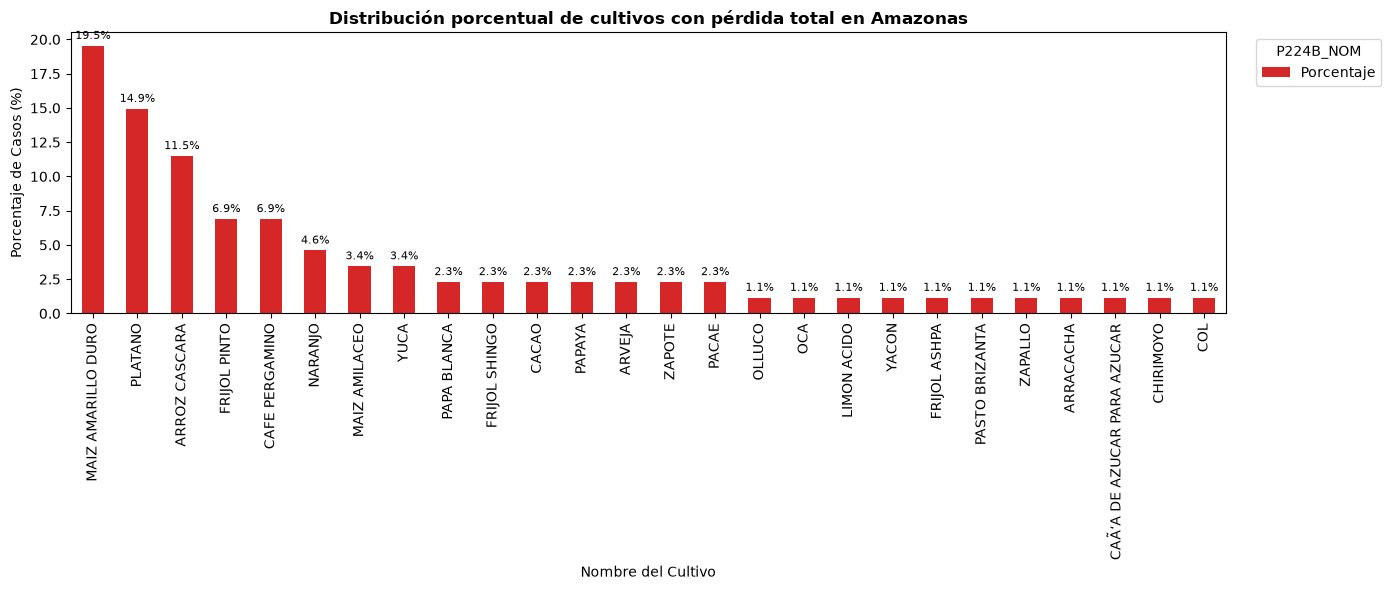

In [144]:
gr_p224b_ama = df_grafico_p224b.plot(
    kind="bar",
    stacked=False,
    figsize=(14, 6),
    color="#d62728"
)

gr_p224b_ama.set_title("Distribución porcentual de cultivos con pérdida total en Amazonas", fontsize=12, fontweight="bold")
gr_p224b_ama.set_xlabel("Nombre del Cultivo", fontsize=10)
gr_p224b_ama.set_ylabel("Porcentaje de Casos (%)", fontsize=10)  

gr_p224b_ama.legend(
    ["Porcentaje"],
    title="P224B_NOM",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

for container in gr_p224b_ama.containers:
    gr_p224b_ama.bar_label(
        container,
        fmt="%.1f%%",  
        label_type="edge", 
        padding=3,         
        fontsize=8        
    )

plt.xticks(rotation=90, ha="center")
plt.tight_layout()
plt.show()

### 3-. ¿CUÁL FUE LA SUPERFICIE SEMBRADA/INSTALADA DE ?(P224D_SUP_1)(P224D_SUP_2)

### -la superficie sembrada o instalada de un cultivo

In [147]:
cols_sup = ["P224D_SUP_1", "P224D_SUP_2"]

df_amazonas[cols_sup] = df_amazonas[cols_sup].apply(pd.to_numeric, errors="coerce")

df_amazonas["SUPERFICIE_TOTAL"] = df_amazonas["P224D_SUP_1"] + (df_amazonas["P224D_SUP_2"]/1000)

tabla_sup_ama = df_amazonas.groupby("NOMBREPV")[["SUPERFICIE_TOTAL"]].sum().reset_index()
tabla_sup_ama.columns = ["provincia", "superficie_total"]

tabla_sup_ama

,provincia,superficie_total
0,BAGUA,39.865
1,BONGARA,5.423
2,CHACHAPOYAS,1.281
3,CONDORCANQUI,16.250
4,LUYA,1.279
5,RODRIGUEZ DE MENDOZA,0.050
6,UTCUBAMBA,60.621


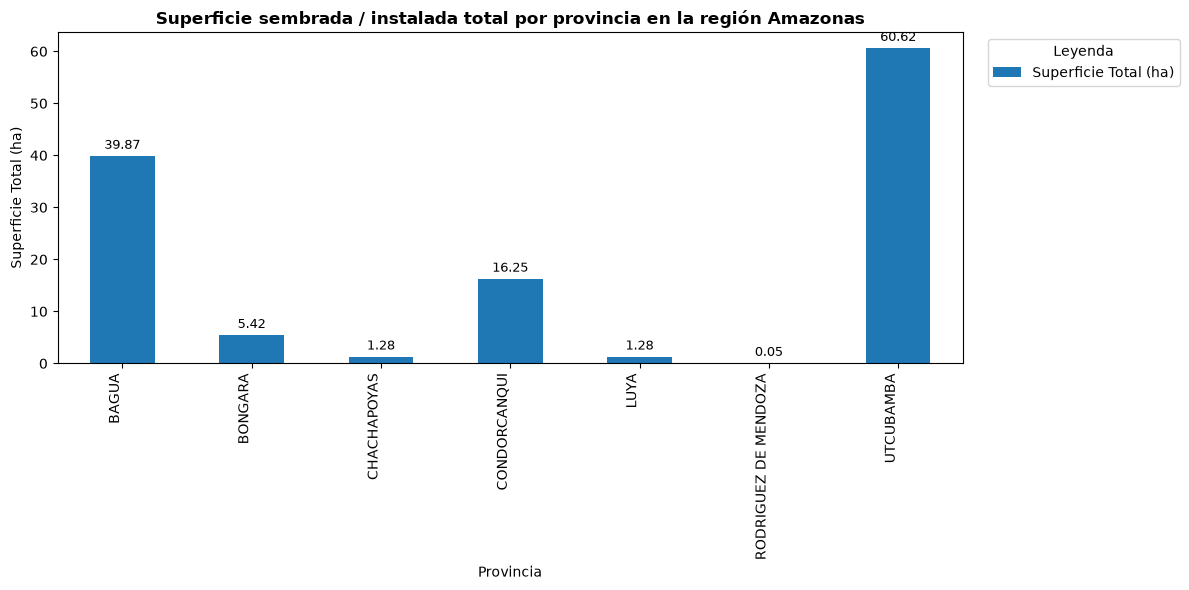

In [154]:
tabla_sup_ama.columns = ["provincia", "Superficie Total (ha)"]

df_grafico_sup = tabla_sup_ama.set_index("provincia")[["Superficie Total (ha)"]]

gr_sup_ama = df_grafico_sup.plot(
    kind="bar",
    stacked=False,
    figsize=(12, 6),
    color="#1f77b4"  
)

gr_sup_ama.set_title("Superficie sembrada / instalada total por provincia en la región Amazonas", fontsize=12, fontweight="bold")
gr_sup_ama.set_xlabel("Provincia", fontsize=10)
gr_sup_ama.set_ylabel("Superficie Total (ha)", fontsize=10)  

gr_sup_ama.legend(
    title="Leyenda",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

for container in gr_sup_ama.containers:
    gr_sup_ama.bar_label(
        container,
        fmt="%.2f",  
        label_type="edge",
        padding=3,     
        fontsize=9
    )

plt.xticks(rotation=90, ha="right")
plt.tight_layout()
plt.show()

### 4-.EN QUE CULTIVOS SEMBRADOS/INSTALADOS TUVO PERDIDA TOTAL DE PRODUCCIÓN O SUPERFICIE EN AMAZONAS?

In [72]:
resumen_tipo_cultivo_ama = pd.crosstab(
    df_amazonas["NOMBREPV"],
    df_amazonas["P224B_TIPO"],
    normalize = "index",
)*100
resumen_tipo_cultivo_ama = resumen_tipo_cultivo_lam.round(2)
resumen_tipo_cultivo_ama = resumen_tipo_cultivo_lam.rename(columns={
    "1": "Transitorio",
    "2": "Permanente_Estacional",
    "3": "Permanente_Continua"
})
resumen_tipo_cultivo_ama

P224B_TIPO,1,2,3
NOMBREPV,,,
BAGUA,45.45,18.18,36.36
BONGARA,83.33,16.67,0.00
CHACHAPOYAS,100.00,0.00,0.00
CONDORCANQUI,0.00,0.00,100.00
LUYA,66.67,33.33,0.00
RODRIGUEZ DE MENDOZA,0.00,100.00,0.00
UTCUBAMBA,62.86,20.00,17.14


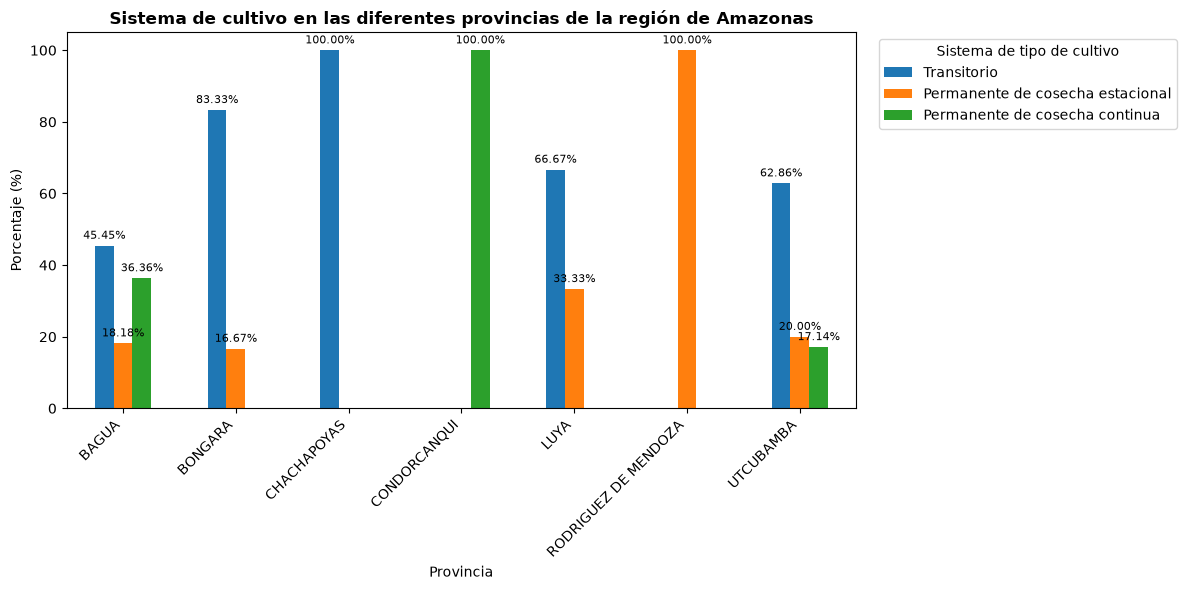

In [156]:
resumen_tipo_cultivo_ama = resumen_tipo_cultivo_ama.rename(columns={
    1: "Transitorio",
    2: "Permanente de cosecha estacional",
    3: "Permanente de cosecha continua"
})

gr_reg_tipo_ama = resumen_tipo_cultivo_ama.plot(
    kind="bar",
    stacked=False,
    figsize=(12, 6)
)

gr_reg_tipo_ama.set_title("Sistema de cultivo en las diferentes provincias de la región de Amazonas", fontsize=12, fontweight="bold")
gr_reg_tipo_ama.set_xlabel("Provincia", fontsize=10)
gr_reg_tipo_ama.set_ylabel("Porcentaje (%)", fontsize=10)  

gr_reg_tipo_ama.legend(
    title="Sistema de tipo de cultivo",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

for container in gr_reg_tipo_ama.containers:
    # Filtramos para que no imprima ceros feos
    gr_reg_tipo_ama.bar_label(
        container,
        labels=[f"{v:.2f}%" if v > 0 else "" for v in container.datavalues],
        label_type="edge",  
        padding=3,          
        fontsize=8          
    )

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 5-.¿CUÁL FUE EL MOTIVO DE LA PÉRDIDA TOTAL DE PRODUCCIÓN O SUPERFICIE EN AMAZONAS? (P224E_1)...(PP224E_7)

In [81]:
cols_factores = [f"P224E_{i}" for i in range(1, 8)]

df_amazonas[cols_factores] = df_amazonas[cols_factores].apply(
    pd.to_numeric,
    errors="coerce"
)

factores_ama = df_amazonas[cols_factores]

nombres_factores = [
    "huaycos, deslizamientos o derrumbes",
    "inundaciones",
    "plagas y/o emfermedades",
    "heladas",
    "granizada",
    "sequia",
    "Otros"
]

tabla_ama = pd.DataFrame({
    "factor": nombres_factores,
    "si_afecto": [factores_ama[c].eq(1).sum() for c in cols_factores],
    "no_afecto": [factores_ama[c].eq(0).sum() for c in cols_factores]
})

tabla_ama["porcentaje_falla"] = (
    tabla_ama["si_afecto"] /
    (tabla_ama["si_afecto"] + tabla_ama["no_afecto"]) * 100
).round(2)

tabla_ama

,factor,si_afecto,no_afecto,porcentaje_falla
0,"huaycos, deslizamientos o derrumbes",8,79,9.20
1,inundaciones,14,73,16.09
2,plagas y/o emfermedades,24,63,27.59
3,heladas,2,85,2.30
4,granizada,0,87,0.00
5,sequia,54,33,62.07
6,Otros,5,82,5.75


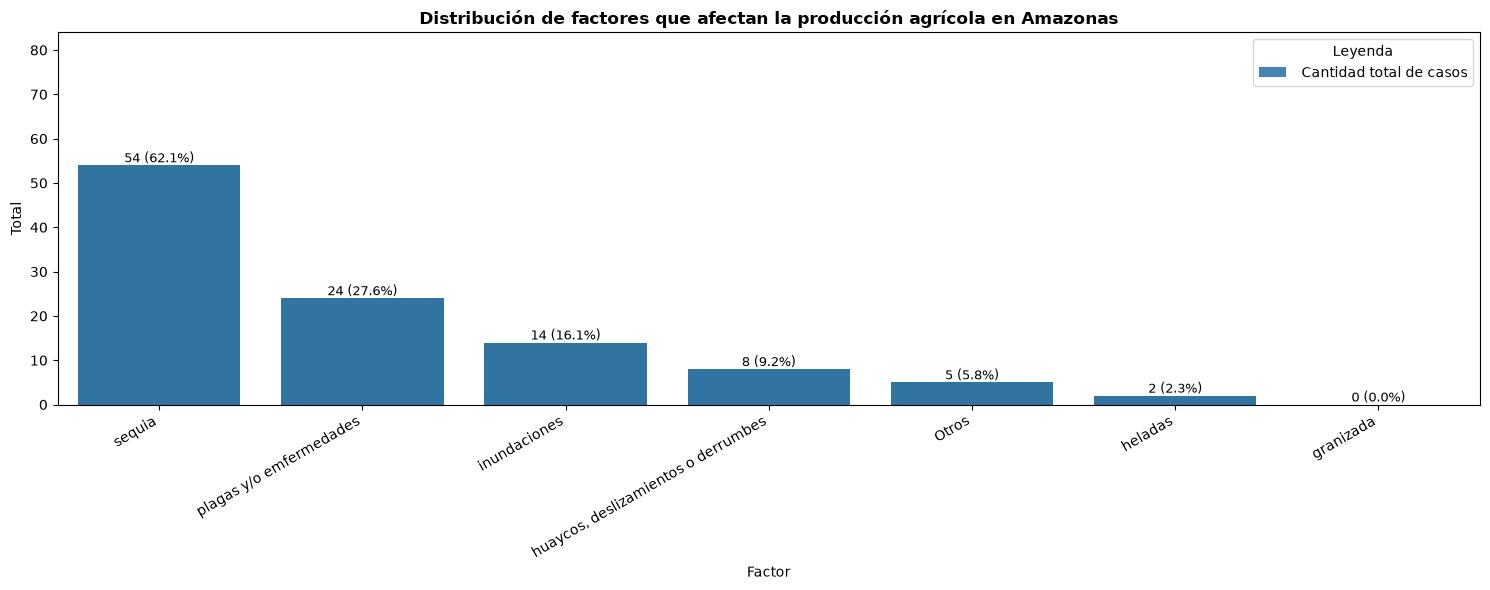

In [161]:
tabla_frecuencias_factores_ama = tabla_ama.sort_values(
    "si_afecto",
    ascending=False
)

plt.figure(figsize=(15, 6))

g_ama_fac = sns.barplot(
    data=tabla_frecuencias_factores_ama, 
    x="factor",
    y="si_afecto" 
)

for i, barra in enumerate(g_ama_fac.patches):    
    conteo = tabla_frecuencias_factores_ama["si_afecto"].iloc[i]
    porcentaje = tabla_frecuencias_factores_ama["porcentaje_falla"].iloc[i]

    g_ama_fac.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(), 
        f"{conteo} ({porcentaje:.1f}%)",
        ha="center", 
        va="bottom",
        fontsize=9
    )

# Aumentamos el límite superior de Y para dar espacio a los textos de las barras
plt.ylim(0, tabla_frecuencias_factores_ama["si_afecto"].max() + 30)

plt.title("Distribución de factores que afectan la producción agrícola en Amazonas", fontsize=12, fontweight="bold")
plt.xlabel("Factor", fontsize=10)
plt.ylabel("Total", fontsize=10)

# Rotar las etiquetas del eje X para evitar que se amontonen o se crucen
plt.xticks(rotation=30, ha="right")

# Agregar leyenda explicativa sobre la lectura de las barras y sus datos
legend_elements = [
    Patch(facecolor='steelblue', label=' Cantidad total de casos')
]
plt.legend(handles=legend_elements, title="Leyenda", loc="upper right")

plt.tight_layout()
plt.show()

### 6-. EN LOS ÚLTIMOS 12 MESES A NIVEL NACIONAL, LA EMPRESA O EL PRODUCTOR REALIZÓ ACTIVIDAD: ¿Agrícola? (P142_1)

In [189]:
resumen_agricola_peru = df_cap200b.groupby("NOMBREDD").agg(
    total_agricola = ("P142_1", lambda x: (x == 1).sum())
).reset_index().round(2)

fila_total = pd.DataFrame({
    "NOMBREDD": ["TOTAL NACIONAL"],
    "total_agricola": [resumen_agricola_peru["total_agricola"].sum()]
})

tabla_agricola_con_total = pd.concat([resumen_agricola_peru, fila_total], ignore_index=True)

display(tabla_agricola_con_total)

,NOMBREDD,total_agricola
0,AMAZONAS,87
1,ANCASH,209
2,APURIMAC,106
3,AREQUIPA,170
4,AYACUCHO,481
5,CAJAMARCA,322
6,CUSCO,409
7,HUANCAVELICA,214
8,HUANUCO,140
9,ICA,64


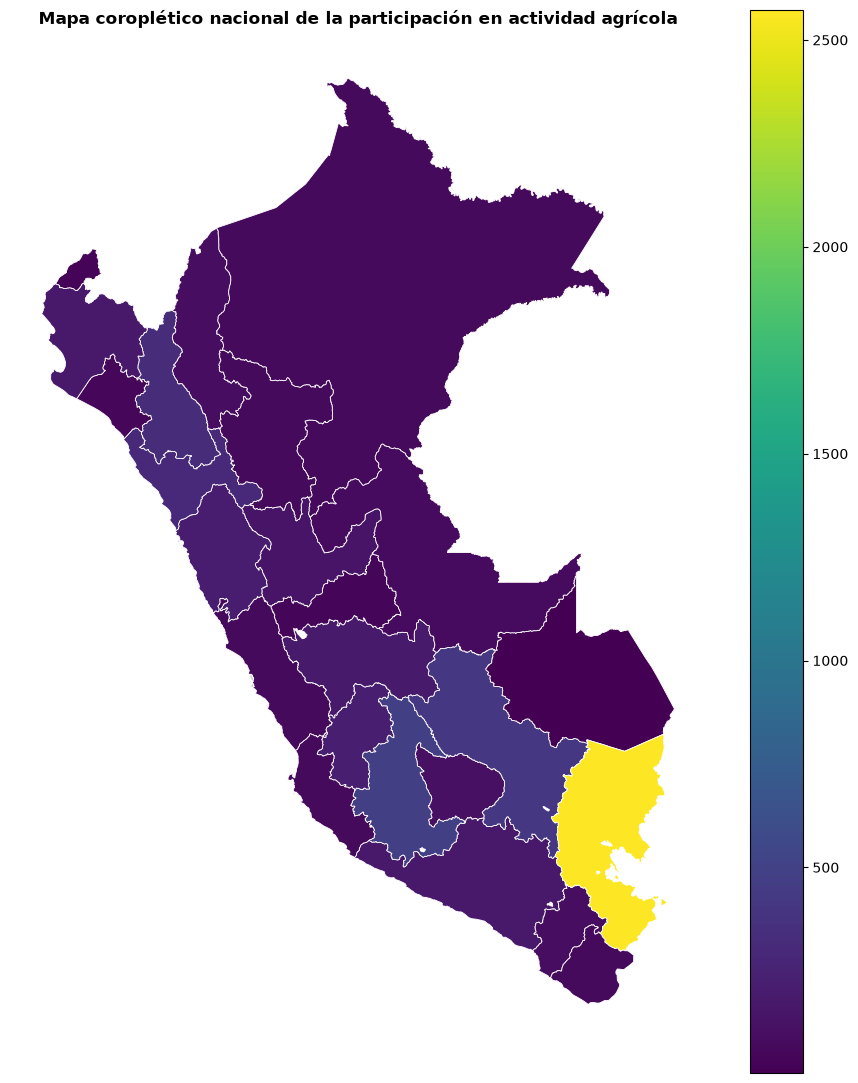

In [190]:
peru_agricola_merge = peru.merge(
    resumen_agricola_peru,
    left_on="NOMBDEP",
    right_on="NOMBREDD",
    how="left"
)

fig, ax = plt.subplots(figsize=(9, 11))

peru_agricola_merge.plot(
    column="total_agricola",  
    cmap="viridis",             
    legend=True,               
    edgecolor="white",          
    linewidth=0.6,
    missing_kwds={
        "color": "lightgrey",
        "label": "Sin datos"
    },
    ax=ax
)

ax.set_title("Mapa coroplético nacional de la participación en actividad agrícola", fontsize=12, fontweight="bold")
ax.set_axis_off()
plt.tight_layout()
plt.show()

### 7-. EN LOS ÚLTIMOS 12 MESES A NIVEL NACIONAL, LA EMPRESA O EL PRODUCTOR REALIZÓ ACTIVIDAD: ¿Pecuaria? (P142_2)

In [201]:
resumen_pecuaria_peru = df_cap200b.groupby("NOMBREDD").agg(
    total_pecuaria = ("P142_2", lambda x: (x == 1).sum())
).reset_index().round(2)

fila_total = pd.DataFrame({
    "NOMBREDD": ["TOTAL NACIONAL"],
    "total_pecuaria": [resumen_pecuaria_peru["total_pecuaria"].sum()]
})

tabla_pecuaria_con_total = pd.concat([resumen_pecuaria_peru, fila_total], ignore_index=True)

display(tabla_pecuaria_con_total)

,NOMBREDD,total_pecuaria
0,AMAZONAS,68
1,ANCASH,186
2,APURIMAC,100
3,AREQUIPA,120
4,AYACUCHO,411
5,CAJAMARCA,303
6,CUSCO,381
7,HUANCAVELICA,199
8,HUANUCO,127
9,ICA,34


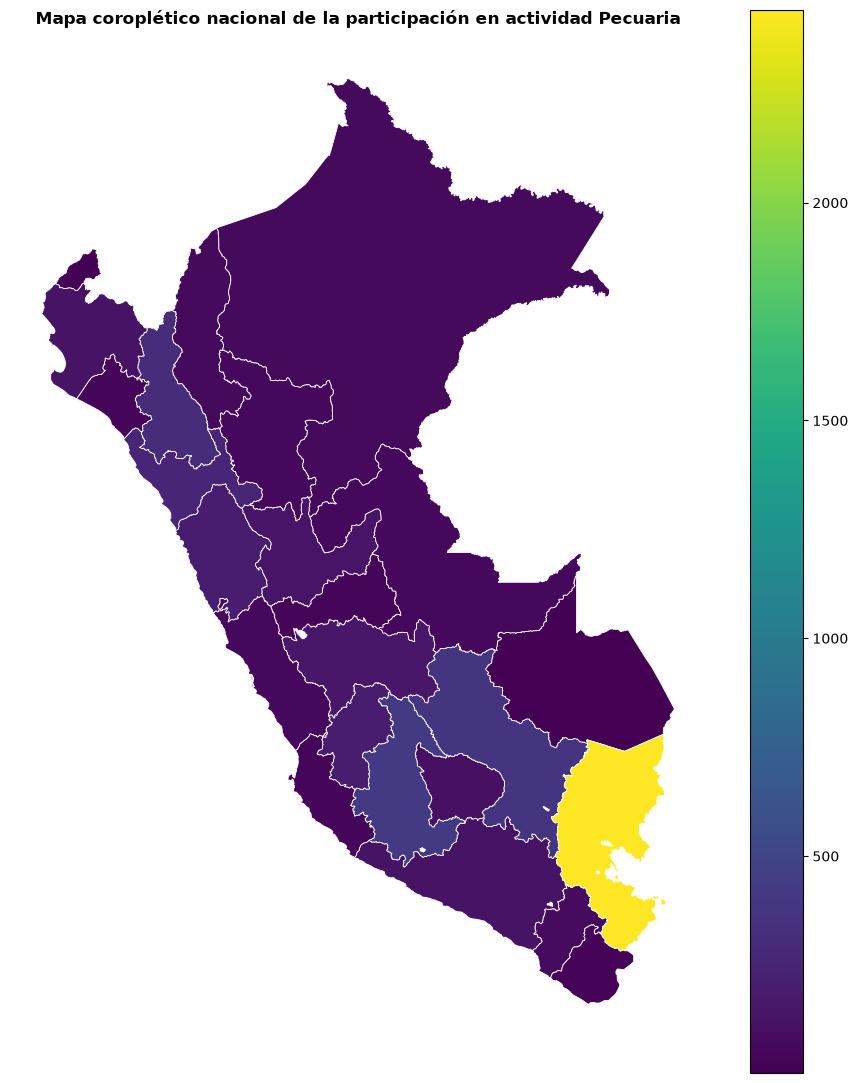

In [204]:
peru_pecuaria_merge = peru.merge(
    resumen_pecuaria_peru,
    left_on="NOMBDEP",
    right_on="NOMBREDD",
    how="left"
)

fig, ax = plt.subplots(figsize=(9, 11))

peru_pecuaria_merge.plot(
    column="total_pecuaria",  
    cmap="viridis",             
    legend=True,               
    edgecolor="white",          
    linewidth=0.6,
    missing_kwds={
        "color": "lightgrey",
        "label": "Sin datos"
    },
    ax=ax
)

ax.set_title("Mapa coroplético nacional de la participación en actividad Pecuaria", fontsize=12, fontweight="bold")
ax.set_axis_off()
plt.tight_layout()
plt.show()

### 8-. Superficie Agrícola Total  sembrada/instalada a Nivel Nacional (P224D_SUP_1)-(P224D_SUP_2)

In [197]:
df_cap200b["superficie_total"] = df_cap200b["P224D_SUP_1"] + (df_cap200b["P224D_SUP_2"] / 1000)

resumen_sup_peru = df_cap200b.groupby("NOMBREDD").agg(
    superficie_total = ("superficie_total", "sum")
).reset_index().round(2)

fila_total = pd.DataFrame({
    "NOMBREDD": ["TOTAL NACIONAL"],
    "superficie_total": [resumen_sup_peru["superficie_total"].sum()]
})

tabla_sup_con_total = pd.concat([resumen_sup_peru, fila_total], ignore_index=True)

display(tabla_sup_con_total)

,NOMBREDD,superficie_total
0,AMAZONAS,124.77
1,ANCASH,37490.68
2,APURIMAC,6477.49
3,AREQUIPA,770.43
4,AYACUCHO,6945.44
5,CAJAMARCA,92.05
6,CUSCO,297384.53
7,HUANCAVELICA,20849.25
8,HUANUCO,50.91
9,ICA,53.69


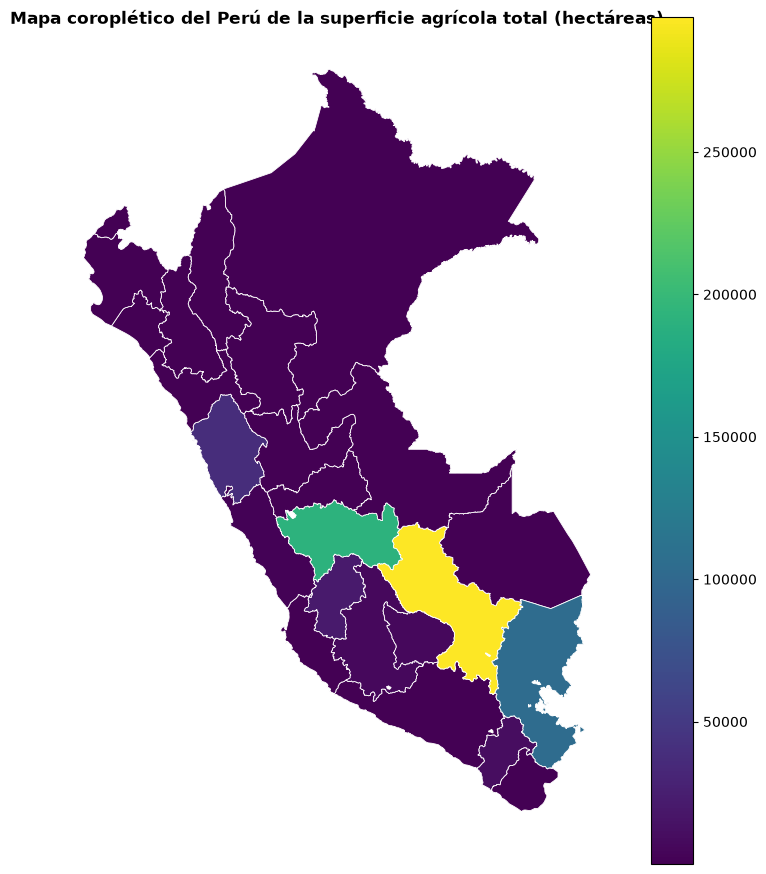

In [198]:
peru_sup_merge = peru.merge(
    resumen_sup_peru,
    left_on="NOMBDEP",
    right_on="NOMBREDD",
    how="left"
).copy()

fig, ax = plt.subplots(figsize=(9, 11))

peru_sup_merge.plot(
    column="superficie_total",
    cmap="viridis",             
    legend=True,
    edgecolor="white",
    linewidth=0.6,
    ax=ax
)

ax.set_title("Mapa coroplético del Perú de la superficie agrícola total (hectáreas)", fontsize=12, fontweight="bold")
ax.set_axis_off()
plt.show()